# RAG Multi Modal Agentique

Ce notebook construit un index multimodal d’un PDF : embeddings CLIP, extraction des textes et des images, stockage dans Chroma et recherche par texte ou par image. Exécuter les cellules dans l’ordre permet de réutiliser les variables et les fonctions définies aux étapes précédentes.

Les dépendances sont déclarées dans `pyproject.toml`. Les exemples nécessitent `architecture_transformer.webp` et `pdfs/attention is all you need.pdf` dans le dossier de travail. Le chargement initial des poids CLIP peut nécessiter un accès réseau.

Les résultats de recherche sont affichés avec leurs sources. La génération de réponses et une orchestration agentique restent à ajouter pour prolonger ce travail vers un RAG agentique complet.


## 01. Importer les bibliothèques multimodales

PyTorch (`torch`) fournit les tenseurs et les calculs sur CPU ou GPU. `open_clip` charge un modèle CLIP pour encoder textes et images dans un espace commun. `PIL.Image` permet de lire les images avant leur prétraitement.


In [2]:
import torch
import open_clip
from PIL import Image

## 02. Choisir le périphérique de calcul

La variable `DEVICE` vaut `cuda` si PyTorch détecte un GPU NVIDIA compatible ; sinon, elle vaut `cpu`. Les entrées et le modèle devront être placés sur ce même périphérique.


In [4]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

## 03. Vérifier le périphérique sélectionné

Cet affichage confirme le périphérique retenu par la cellule précédente. Une sortie `cpu` indique que les calculs seront effectués sur le processeur.


In [5]:
print(f"Using device: {DEVICE}")

Using device: cpu


## 04. Définir le modèle CLIP et ses poids

`MODEL_NAME` choisit l’architecture `ViT-B-32`, tandis que `PRETRAINED` identifie les poids préentraînés à charger. Ces paramètres servent à construire le modèle et à sélectionner son tokeniseur.


In [3]:
MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"

## 05. Charger le modèle et le prétraitement des images

`create_model_and_transforms` fournit le modèle et les transformations nécessaires à ses entrées visuelles. Les poids peuvent être téléchargés au premier lancement. Le modèle est ensuite déplacé vers `DEVICE` et passé en mode évaluation avec `.eval()`.


In [6]:
model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME,
    pretrained=PRETRAINED
)

model = model.to(DEVICE).eval()

## 06. Préparer le tokeniseur de texte

Le tokeniseur associé à `MODEL_NAME` convertit les chaînes de caractères en séquences de jetons au format attendu par l’encodeur de texte CLIP.


In [7]:
tokenizer = open_clip.get_tokenizer(MODEL_NAME)

## 07. Tokeniser un texte d’exemple

La phrase d’exemple est placée dans une liste afin de constituer un lot contenant un seul texte. Le tenseur de jetons est ensuite envoyé sur le même périphérique que le modèle.


In [8]:
texte = "Un chat sur un canapé"
tokens = tokenizer([texte]).to(DEVICE)

## 08. Prétraiter une image d’exemple

Le fichier `architecture_transformer.webp` doit être présent dans le dossier de travail. L’image est ouverte en RGB puis transformée avec `preprocess`. `unsqueeze(0)` ajoute la dimension du lot avant le transfert vers `DEVICE`.


In [10]:
with Image.open("architecture_transformer.webp") as image:
    tenseur_image = preprocess(image.convert("RGB"))

tenseur_image = tenseur_image.unsqueeze(0).to(DEVICE)

## 09. Inspecter le tenseur de l’image

La forme affichée permet de vérifier l’entrée du modèle : `[1, 3, 224, 224]` dans la sortie enregistrée correspond à une image, trois canaux RGB et une résolution de 224 × 224 pixels. La seconde expression affiche les valeurs du tenseur prétraité.


In [21]:
print(tenseur_image.shape)
tenseur_image

torch.Size([1, 3, 224, 224])


tensor([[[[1.9303, 1.9303, 1.9303,  ..., 1.9303, 1.9303, 1.9303],
          [1.9303, 1.9303, 1.9303,  ..., 1.9303, 1.9303, 1.9303],
          [1.9303, 1.9303, 1.9303,  ..., 1.9303, 1.9303, 1.9303],
          ...,
          [1.9303, 1.9303, 1.9303,  ..., 1.9303, 1.9303, 1.9303],
          [1.9303, 1.9303, 1.9303,  ..., 1.9303, 1.9303, 1.9303],
          [1.9303, 1.9303, 1.9303,  ..., 1.9303, 1.9303, 1.9303]],

         [[2.0749, 2.0749, 2.0749,  ..., 2.0749, 2.0749, 2.0749],
          [2.0749, 2.0749, 2.0749,  ..., 2.0749, 2.0749, 2.0749],
          [2.0749, 2.0749, 2.0749,  ..., 2.0749, 2.0749, 2.0749],
          ...,
          [2.0749, 2.0749, 2.0749,  ..., 2.0749, 2.0749, 2.0749],
          [2.0749, 2.0749, 2.0749,  ..., 2.0749, 2.0749, 2.0749],
          [2.0749, 2.0749, 2.0749,  ..., 2.0749, 2.0749, 2.0749]],

         [[2.1459, 2.1459, 2.1459,  ..., 2.1459, 2.1459, 2.1459],
          [2.1459, 2.1459, 2.1459,  ..., 2.1459, 2.1459, 2.1459],
          [2.1459, 2.1459, 2.1459,  ..., 2

## 10. Encoder et normaliser le texte et l’image

Les deux encodeurs produisent des vecteurs dans l’espace commun de CLIP. `torch.inference_mode()` désactive le suivi des gradients pendant ce calcul. Chaque vecteur est divisé par sa norme L2 ; pour ces vecteurs unitaires, le produit scalaire correspond à la similarité cosinus.


In [11]:
with torch.inference_mode():
    vecteur_texte = model.encode_text(tokens)
    vecteur_image = model.encode_image(tenseur_image)

    vecteur_texte = vecteur_texte / vecteur_texte.norm(
        dim=-1, keepdim=True
    )
    vecteur_image = vecteur_image / vecteur_image.norm(
        dim=-1, keepdim=True
    )

## 11. Convertir les embeddings en listes Python

L’index `[0]` sélectionne le premier élément du lot. Les vecteurs sont rapatriés sur le CPU puis convertis en listes avec `.tolist()`, un format utilisable par une base vectorielle. Les sorties enregistrées indiquent 512 composantes pour chaque modalité.


In [12]:
vecteur_texte = vecteur_texte[0].cpu().tolist()
vecteur_image = vecteur_image[0].cpu().tolist()

print("Dimension texte :", len(vecteur_texte))
print("Dimension image :", len(vecteur_image))

Dimension texte : 512
Dimension image : 512


## 12. Préparer les chemins et dossiers du PDF

Cette étape utilise PyMuPDF pour lire `pdfs/attention is all you need.pdf`. Elle vérifie que le fichier existe puis crée les dossiers `resultats_pdf/textes` et `resultats_pdf/images` destinés aux extractions. Le chemin est relatif au dossier de travail du notebook.


In [17]:
from pathlib import Path
import pymupdf

PDF_PATH = Path("pdfs/attention is all you need.pdf")

OUTPUT_DIR = Path("resultats_pdf")
TEXT_DIR = OUTPUT_DIR / "textes"
IMAGE_DIR = OUTPUT_DIR / "images"

if not PDF_PATH.is_file():
    raise FileNotFoundError(f"Fichier introuvable : {PDF_PATH.resolve()}")

TEXT_DIR.mkdir(parents=True, exist_ok=True)
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

## 13. Extraire le texte et les images du PDF

Chaque page produit un fichier texte UTF-8 et contribue à `texte_complet.txt`. Les images intégrées sont extraites à partir de leur identifiant `xref`, avec déduplication à l’intérieur de chaque page. Les erreurs d’extraction sont signalées sans interrompre les autres images.

Les pages sans texte détectable sont recensées. Cette cellule n’effectue pas d’OCR ; un traitement supplémentaire serait nécessaire pour du texte scanné. L’extraction des images intégrées ne produit pas un rendu complet des pages.


In [22]:
textes = []
nombre_images = 0
pages_sans_texte = []

with pymupdf.open(PDF_PATH) as document:
    nombre_pages = len(document)

    for numero_page, page in enumerate(document, start=1):
        # ---- Extraction du texte ----
        texte = page.get_text("text", sort=True)

        fichier_texte = TEXT_DIR / f"page_{numero_page:03d}.txt"
        fichier_texte.write_text(texte, encoding="utf-8")

        textes.append(f"===== PAGE {numero_page} =====\n\n{texte}")

        if not texte.strip():
            pages_sans_texte.append(numero_page)

        # ---- Extraction des images intégrées ----
        # Éviter d'extraire plusieurs fois la même image sur une page.
        images_vues = set()

        for image_info in page.get_images(full=True):
            xref = image_info[0]

            if xref in images_vues:
                continue

            images_vues.add(xref)

            try:
                image = document.extract_image(xref)

                if not image:
                    print(f"Image non extractible : page {numero_page}, xref {xref}")
                    continue

                extension = image["ext"]
                fichier_image = (
                    IMAGE_DIR
                    / f"page_{numero_page:03d}_image_{xref}.{extension}"
                )
                fichier_image.write_bytes(image["image"])

                nombre_images += 1

            except Exception as erreur:
                print(
                    f"Erreur d'extraction : page {numero_page}, "
                    f"image {xref} : {erreur}"
                )

# Enregistrer le texte de tout le document.
(OUTPUT_DIR / "texte_complet.txt").write_text(
    "\n\n".join(textes),
    encoding="utf-8"
)

print(f"Pages traitées : {nombre_pages}")
print(f"Images enregistrées : {nombre_images}")

if pages_sans_texte:
    print("Pages sans texte détectable :", pages_sans_texte)
    print("Si elles contiennent du texte scanné, utilisez l'OCR ci-dessous.")

Pages traitées : 11
Images enregistrées : 3


## 14. Contrôler les résultats de l’extraction

Le notebook affiche les 2 000 premiers caractères du texte complet et un aperçu des cinq premiers fichiers du dossier d’images, au maximum. Les miniatures sont limitées à 600 × 600 pixels en conservant leurs proportions. Cette vérification visuelle aide à repérer une extraction vide ou inattendue.


APERÇU DU TEXTE

===== PAGE 1 =====

             Attention Is All You Need





     Ashish Vaswani∗      Noam Shazeer∗       Niki Parmar∗     Jakob Uszkoreit∗
      Google Brain          Google Brain       Google Research     Google Research
  avaswani@google.com   noam@google.com   nikip@google.com   usz@google.com

        Llion Jones∗          Aidan N. Gomez∗†            Łukasz Kaiser∗
     Google Research          University of Toronto              Google Brain
    llion@google.com     aidan@cs.toronto.edu     lukaszkaiser@google.com

                                               Illia Polosukhin∗‡
                         illia.polosukhin@gmail.com


                                Abstract

       The dominant sequence transduction models are based on complex recurrent or
        convolutional neural networks that include an encoder and a decoder. The best
        performing models also connect the encoder and decoder through an attention
       mechanism. We propose a new sim

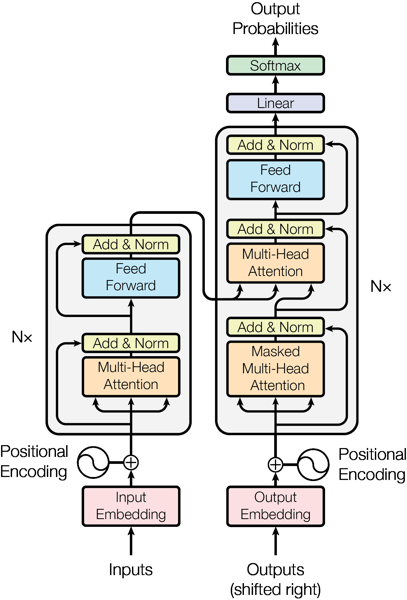

page_004_image_129.png


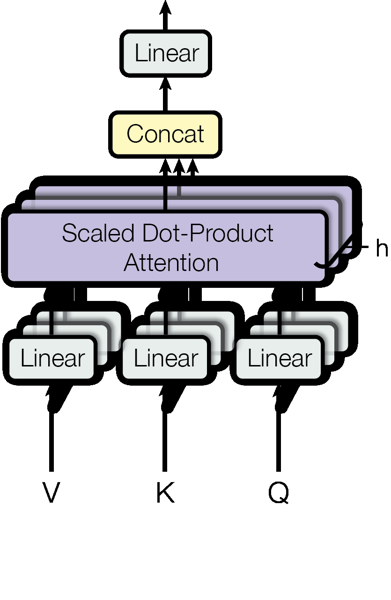

page_004_image_130.png


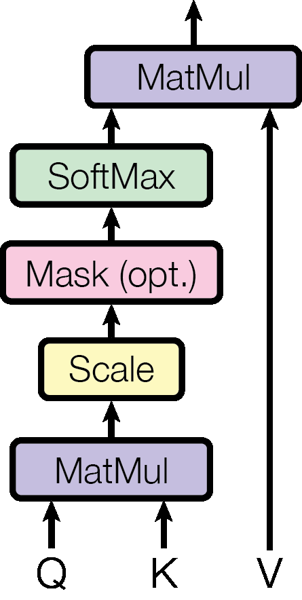

In [23]:
from PIL import Image
from IPython.display import display

texte_complet = (OUTPUT_DIR / "texte_complet.txt").read_text(
    encoding="utf-8"
)

print("APERÇU DU TEXTE\n")
print(texte_complet[:2000])

print("\nAPERÇU DES IMAGES\n")

for fichier in sorted(IMAGE_DIR.iterdir())[:5]:
    print(fichier.name)

    with Image.open(fichier) as image:
        apercu = image.copy()
        apercu.thumbnail((600, 600))
        display(apercu)

## 15. Initialiser CLIP et la collection Chroma persistante

Cette cellule recharge le modèle, ses transformations et ses tokeniseurs, puis ouvre une base Chroma dans `chroma_pdf`. La collection `pdf_clip_vit_b32` utilise la distance cosinus. `embedding_function=None` signifie que les embeddings devront être fournis explicitement par le code.

Les dossiers d’extraction sont redéfinis pour les étapes d’indexation. Le compteur affiché indique le nombre d’éléments déjà présents dans la collection persistante.


In [25]:
from pathlib import Path
import hashlib
import re

import torch
import open_clip
import chromadb

from PIL import Image
from open_clip.tokenizer import SimpleTokenizer

# Dossiers produits par les cellules d'extraction
OUTPUT_DIR = Path("resultats_pdf")
TEXT_DIR = OUTPUT_DIR / "textes"
IMAGE_DIR = OUTPUT_DIR / "images"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

MODEL_NAME = "ViT-B-32"
PRETRAINED = "laion2b_s34b_b79k"

model, _, preprocess = open_clip.create_model_and_transforms(
    MODEL_NAME,
    pretrained=PRETRAINED
)

model = model.to(DEVICE).eval()
tokenizer = open_clip.get_tokenizer(MODEL_NAME)

# Tokeniseur BPE adapté au modèle CLIP choisi
bpe = SimpleTokenizer()

# Base persistante sur disque
client = chromadb.PersistentClient(path="chroma_pdf")

collection = client.get_or_create_collection(
    name="pdf_clip_vit_b32",
    embedding_function=None,  # Les embeddings sont calculés par notre code
    metadata={"hnsw:space": "cosine"}
)

print("Appareil :", DEVICE)
print("Éléments déjà présents :", collection.count())

Appareil : cpu
Éléments déjà présents : 0


## 16. Découper le texte par fenêtres de jetons

`decouper_texte` transforme le texte en jetons BPE, puis génère des fragments de 60 jetons avec un chevauchement de 10 par défaut. Le pas vaut donc 50 jetons. Le chevauchement conserve du contexte entre fragments voisins ; la validation impose une valeur positive ou nulle, strictement inférieure à la taille.

Le découpage est effectué avant le décodage des fragments en chaînes de caractères. Il faut vérifier leur longueur après retokenisation par le tokeniseur du modèle pour garantir le respect de sa fenêtre de contexte.


In [38]:
def decouper_texte(texte, taille=60, chevauchement=10):
    """Découper le texte en fragments courts adaptés à CLIP."""
    if not 0 <= chevauchement < taille:
        raise ValueError("Le chevauchement doit être inférieur à la taille.")

    tokens = bpe.encode(texte)

    for debut in range(0, len(tokens), taille - chevauchement):
        fragment = bpe.decode(tokens[debut:debut + taille]).strip()

        if fragment:
            yield fragment

        if debut + taille >= len(tokens):
            break

## 17. Proposer un découpage respectant les séparateurs naturels

`decouper_texte_V2` utilise `RecursiveCharacterTextSplitter` et mesure la longueur avec le tokeniseur BPE. Les séparateurs sont essayés dans l’ordre : paragraphes, lignes, espaces, puis caractères. La taille cible reste de 60 jetons avec un chevauchement de 10.

Cette variante est définie à titre d’alternative. La cellule d’indexation du texte appelle actuellement `decouper_texte`, et il faut modifier cet appel pour utiliser la version V2.


In [39]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

def decouper_texte_V2(texte, taille=60, chevauchement=10):
    """Découper le texte en privilégiant les limites naturelles."""
    if not 0 <= chevauchement < taille:
        raise ValueError("Le chevauchement doit être inférieur à la taille.")

    splitter = RecursiveCharacterTextSplitter(
        chunk_size=taille,
        chunk_overlap=chevauchement,
        length_function=lambda texte: len(bpe.encode(texte)),
        separators=["\n\n", "\n", " ", ""],
        strip_whitespace=True,
    )

    yield from splitter.split_text(texte)

## 18. Encoder un lot de textes avec CLIP

`encoder_textes` tokenise plusieurs chaînes, calcule leurs embeddings et renvoie une liste de vecteurs sur CPU. Le décorateur `torch.inference_mode()` désactive le suivi des gradients. La conversion en flottants et la normalisation L2 préparent les vecteurs pour la comparaison cosinus dans Chroma ; `clamp_min(1e-12)` évite une division par zéro.

Cette fonction réutilise `tokenizer`, `model` et `DEVICE`, définis lors de l’initialisation. Les textes doivent respecter la fenêtre de contexte du modèle.


In [40]:
@torch.inference_mode()
def encoder_textes(textes):
    tokens = tokenizer(textes).to(DEVICE)
    vecteurs = model.encode_text(tokens).float()

    vecteurs = vecteurs / vecteurs.norm(
        dim=-1, keepdim=True
    ).clamp_min(1e-12)

    return vecteurs.cpu().tolist()

## 19. Retrouver le numéro de page depuis un fichier

`numero_page` recherche le motif `page_` suivi de chiffres dans le nom du fichier, sans son extension. Par exemple, `page_003.txt` et `page_003_image_128.png` renvoient tous deux `3`. La valeur `-1` indique qu’aucun numéro de page n’a été trouvé.

Exécuter cette définition après l’extraction du PDF : la boucle d’extraction emploie aussi le nom `numero_page` pour un entier. Si cette boucle est relancée, redéfinir ensuite la fonction avant l’indexation.


In [31]:
def numero_page(chemin):
    correspondance = re.search(r"page_(\d+)", Path(chemin).stem)
    return int(correspondance.group(1)) if correspondance else -1

## 21. Indexer les fragments de texte dans Chroma

Le contenu du PDF est haché en SHA-256 pour construire un identifiant de document. Les éléments associés à cet identifiant sont supprimés, puis les fragments de texte sont préparés avec leurs métadonnées : PDF, page, numéro de fragment et chemin source. Les insertions sont effectuées par lots de 64 avec `upsert` et les embeddings normalisés fournis par `encoder_textes`.

Cette étape réutilise `numero_page` et `encoder_textes`, définies plus haut. Le découpage appelle `decouper_texte` ; remplacer cet appel par `decouper_texte_V2` permet d’essayer la variante récursive.

La suppression initiale concerne tous les éléments du document, y compris ses images déjà indexées. Après une réexécution, relancer aussi la cellule d’indexation des images pour rétablir l’index multimodal.


In [33]:
# PDF_PATH provient des cellules précédentes
PDF_PATH = Path(PDF_PATH)

# Identifiant lié au contenu du PDF
document_id = hashlib.sha256(PDF_PATH.read_bytes()).hexdigest()[:24]

# Supprimer l'ancienne version de l'index de ce PDF.
# Cela évite les fragments obsolètes après une nouvelle extraction.
collection.delete(where={"document_id": document_id})

ids = []
documents = []
metadatas = []

for fichier in sorted(TEXT_DIR.glob("page_*.txt")):
    texte = fichier.read_text(encoding="utf-8")
    page = numero_page(fichier)

    for index, fragment in enumerate(decouper_texte(texte)):
        ids.append(f"{document_id}:texte:{page}:{index}")
        documents.append(fragment)

        metadatas.append({
            "type": "texte",
            "document_id": document_id,
            "pdf": PDF_PATH.name,
            "page": page,
            "fragment": index,
            "source": str(fichier.resolve())
        })

# Indexation par lots
TAILLE_LOT = 64

for debut in range(0, len(documents), TAILLE_LOT):
    fin = debut + TAILLE_LOT
    lot = documents[debut:fin]

    collection.upsert(
        ids=ids[debut:fin],
        documents=lot,
        metadatas=metadatas[debut:fin],
        embeddings=encoder_textes(lot)
    )

print(f"{len(documents)} fragments de texte indexés.")

171 fragments de texte indexés.
